# Lab 5 — Build WA+ Sheets 1–4

**Objective:** turn the fluxes into the four WA+ accounts — the resource base, ET (beneficial/non-beneficial, managed/natural), productivity, and withdrawals — and pass the cross-sheet consistency checks.

**Depends on Labs 1–4:** `gridspec.json`, `basin_mask.nc`, `P_corrected.nc`, `ET.nc`, `etrain.nc`, `etincr.nc`, `sro.nc`, `perc.nc`, `NDM.nc`, `lu.nc`, `basin_config.json`.

Pure Python — runs offline (only the optional §4b uses Earth Engine). These transparent builders give the numbers and the checks; §8b draws WA+-style figures of the four sheets.

### 🧭 What we are really doing here

Now we assemble the accounts themselves. It is the same water seen four ways: Sheet 1 asks *how much is there* (the resource base), Sheet 2 *where it is consumed and whether that is useful* (beneficial vs non-beneficial ET), Sheet 3 *how much value each drop returns* (productivity), and Sheet 4 *who withdraws it and how much comes back* (recoverable vs not).

Here is the discipline that makes it an account and not four spreadsheets: the sheets are one balance seen four ways, so their shared numbers **must** agree — total ET in Sheet 2 has to equal the ET line in Sheet 1, the outflow in Sheet 1 has to match the flows in Sheet 4, and so on. The consistency checks at the end are not bureaucracy; a sheet set that fails them is not ready to put in front of anyone. And write down every assumption as you go — that log is half the deliverable.

## 0 · Environment setup  *(Colab or local — auto-detected)*

**What this does.** Mounts Drive, points at the **`west_rapti`** folder, imports the engine as `kw`.

In [1]:
import os, sys, shutil
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    KW_DIR = '/content/drive/MyDrive/west_rapti'
    get_ipython().system('pip -q install rioxarray')
else:
    KW_DIR = '.'
OUT_DIR = os.path.join(KW_DIR, 'outputs') if IN_COLAB else 'outputs'

# --- always load the engine from KW_DIR (Drive), never a stale copy elsewhere ---
_kw = os.path.abspath(KW_DIR)
if os.path.abspath('.') != _kw:
    for _f in ('west_rapti.py', 'westrapti_prep.py'):
        if os.path.exists(_f): os.remove(_f)
for _p in (KW_DIR, _kw):
    while _p in sys.path: sys.path.remove(_p)
sys.path.insert(0, _kw)
for _m in ('west_rapti', 'westrapti_prep'): sys.modules.pop(_m, None)
# --- participant settings (written once by 00_Setup.ipynb) ---
import json as _json
_pj = os.path.join(KW_DIR, 'participant.json')
PARTICIPANT = _json.load(open(_pj)) if os.path.exists(_pj) else {}
EE_PROJECT = PARTICIPANT.get('ee_project', '')
if not EE_PROJECT:
    print('⚠️  No Earth Engine project set — run 00_Setup.ipynb first (or set EE_PROJECT in CONFIG).')
print('Running on', 'Colab' if IN_COLAB else 'local', '| outputs ->', OUT_DIR)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 73.5 MB/s eta 0:00:00
Running on Colab | outputs -> /content/drive/MyDrive/west_rapti/outputs


## 1 · Imports & **configuration**

**What this does.** Loads the stack and the CONFIG (e.g. `CROP_PRICE` for economic productivity, the
beneficial-ET method). Sheets are built from the analysis-ready cubes produced in Labs 2–4.

In [2]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xarray as xr, json
import importlib, west_rapti as kw; importlib.reload(kw)

# ---------------- CONFIG ----------------
CROP_PRICE       = None     # $ per kg C of biomass, for Sheet 3 economic WP; None to skip
WP_CLASSES       = (6, 8)   # Sheet 3 'more crop per drop': WA+ rainfed (6) + irrigated (8) cropland; None = whole basin
IRR_EFFICIENCY   = 0.5      # Sheet 4: consumed fraction of irrigation withdrawals (≈0.4–0.6 surface irrigation) — log it
BENEFICIAL_SPLIT = 'auto'   # Sheet 2: 'auto' = WaPOR transpiration if transp.nc exists, else LU fractions | 'lu' | 'transpiration'
NDM_UNITS        = 'kg C'   # NDM from MOD17 GPP (Lab 2 NDM_SOURCE='mod17'); change if you used WaPOR NPP
# Units: all sheet volumes are MCM (million m³) per year. Land-use beneficial fractions: kw.LU_FRACTIONS.
# ----------------------------------------

## 2 · Pull Labs 1–4 outputs from Drive

**What this does.** Loads the grid, mask and the flux cubes (P, ET, land use, runoff, percolation,
incremental/rainfall ET, biomass) — the inputs the four WA+ sheets consume.

In [3]:
kw.load_inputs(['gridspec.json','basin_mask.nc','P_corrected.nc','ET.nc','etrain.nc','etincr.nc',
                'sro.nc','perc.nc','NDM.nc','lu.nc','basin_config.json'], OUT_DIR)
kw.load_inputs(['transp.nc'], OUT_DIR)   # optional WaPOR transpiration (physical Sheet-2 split); ok if absent
gs = json.load(open('gridspec.json')); RES = gs['res']
mask = xr.open_dataset('basin_mask.nc')['basin_mask']
lu   = xr.open_dataarray('lu.nc', decode_coords='all')
import os as _os
TRANSP = xr.open_dataarray('transp.nc', decode_coords='all') if _os.path.exists('transp.nc') else None
cubes = {n: xr.open_dataarray(f'{f}.nc', decode_coords='all') for n,f in
         {'P':'P_corrected','ET':'ET','etrain':'etrain','etincr':'etincr','sro':'sro','perc':'perc'}.items()}
ndm = xr.open_dataarray('NDM.nc', decode_coords='all')
def on_grid(da, ref):
    """Put da on ref's y/x coordinates. Same grid, but tiny float differences in coordinates make xarray
    silently align to an EMPTY overlap (every product then sums to 0) — so force identical coordinates."""
    yd, xd = da.dims[-2], da.dims[-1]; ry, rx = ref.dims[-2], ref.dims[-1]
    if tuple(da.shape[-2:]) != tuple(ref.shape[-2:]):
        raise ValueError(f'{da.name}: grid {da.shape[-2:]} differs from the basin grid {ref.shape[-2:]} — re-run the lab that made it')
    if (yd, xd) != (ry, rx): da = da.rename({yd: ry, xd: rx})
    return da.assign_coords({ry: ref[ry].values, rx: ref[rx].values})
lu = on_grid(lu, mask); ndm = on_grid(ndm, mask)
cubes = {k: on_grid(v, mask) for k, v in cubes.items()}
if TRANSP is not None: TRANSP = on_grid(TRANSP, mask)

# observed outflow at the outlet gauge (made by 00_Setup / westrapti_prep), for Sheet 1
Q_OBS = None
_oc = os.path.join(KW_DIR, 'discharge_outlet.csv')
if os.path.exists(_oc):
    _q = pd.read_csv(_oc, index_col=0, parse_dates=True)['vol_MCM']
    _q = _q[_q.index.year.isin(sorted(set(cubes['P']['time'].dt.year.values)))]
    _qa = _q.groupby(_q.index.year).sum(min_count=12).dropna()          # complete years only
    Q_OBS = float(_qa.mean()) if len(_qa) else None
print('loaded', list(cubes)+['NDM','lu'], '| grid', mask.shape, '| res', RES,
      '| gauged outflow:', f'{Q_OBS:,.0f} MCM/yr' if Q_OBS else 'not available (00_Setup with HydroMetData)')

loaded ['P', 'ET', 'etrain', 'etincr', 'sro', 'perc', 'NDM', 'lu'] | grid (394, 556) | res 300 | gauged outflow: 4,888 MCM/yr


## 3 · Sheet 1 — Resource Base

**Sheet 1 — Resource base.** The basin's water 'bank statement': everything in (rain), everything consumed (ET) and everything that leaves (outflow). Get this one right and it frames every other sheet.

**Modelled outflow** = runoff + percolation − blue ET: blue water is consumed from the basin's own rivers and groundwater, so it does not also leave at the outlet. The fourth term, the **closure term** P − ET − outflow, is then the change in soil-moisture storage (plus any snowpack change); a large value means misaligned inputs. **Net inflow** = P − closure = ET + outflow, the water actually consumed or delivered. The **gauged** outflow (Kusum) is shown next to the modelled one: their gap is the honest error bar on everything downstream.

gross_inflow_P      11034.2
ET_depleted          4957.7
ET_green             4312.9
ET_blue               636.2
outflow_est          6135.4
outflow_observed     4887.7
outflow_bias_pct       25.5
closure_term          -58.9
net_inflow          11093.1


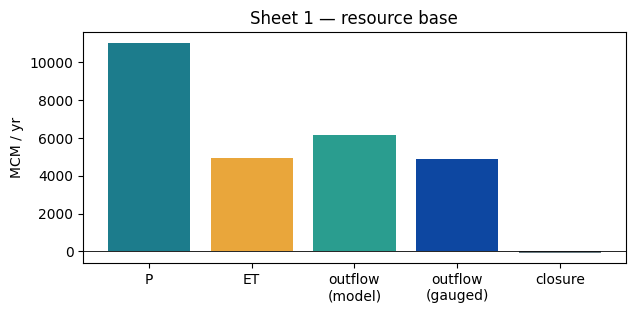

In [4]:
V  = kw.sheet_volumes(cubes, mask, RES)          # annual-mean basin volumes (MCM/yr)
s1 = kw.sheet1_resource_base(V, q_obs=Q_OBS)
_order = ['gross_inflow_P', 'ET_depleted', 'ET_green', 'ET_blue', 'outflow_est', 'outflow_observed',
          'outflow_bias_pct', 'closure_term', 'net_inflow']
print(pd.Series({k: round(s1[k], 1) for k in _order if s1.get(k) is not None}).to_string())
fig, ax = plt.subplots(figsize=(7, 3))
lab = ['P', 'ET', 'outflow\n(model)'] + (['outflow\n(gauged)'] if Q_OBS else []) + ['closure']
val = [s1['gross_inflow_P'], s1['ET_depleted'], s1['outflow_est']] + ([Q_OBS] if Q_OBS else []) + [s1['closure_term']]
ax.bar(lab, val, color=['#1C7C8C', '#E9A63B', '#2A9D8F'] + (['#0D47A1'] if Q_OBS else []) + ['#6A7B82'])
ax.axhline(0, color='k', lw=0.6); ax.set_ylabel('MCM / yr'); ax.set_title('Sheet 1 — resource base'); plt.show()

## 4 · Sheet 2 — Evapotranspiration (depletion)

**Sheet 2 — Evapotranspiration (depletion).** Splits ET into beneficial vs non-beneficial and managed vs natural, by land-use class — where the depleted water actually goes. With `BENEFICIAL_SPLIT='auto'`, the split is **physical** (beneficial = transpiration) when Lab 2 saved `transp.nc`; otherwise it uses the per-class fractions in `kw.LU_FRACTIONS` — **assumptions** that decide most of the split, so record them.

beneficial-ET source: LU fractions
Total ET 4957.7 MCM | beneficial 4310.6 | non-beneficial 647.1 | managed 393.3 | natural 4564.4


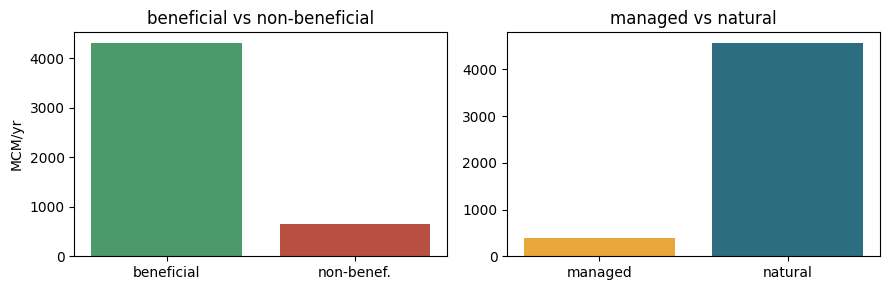

ET by class (MCM): {'Forest': 4357.7, 'Shrub / grassland': 185.1, 'Bare / rock': 21.5, 'Rainfed cropland': 89.8, 'Settlement / urban': 2.3, 'Irrigated cropland': 263.3, 'Water body / reservoir': 37.9}


In [5]:
_useT = TRANSP is not None and BENEFICIAL_SPLIT in ('auto', 'transpiration')
if BENEFICIAL_SPLIT == 'transpiration' and TRANSP is None:
    print('⚠️  transp.nc not found (run Lab 2 with ET_SPLIT="wapor") — using LU fractions instead')
s2 = kw.sheet2_et(cubes['ET'], lu, mask, RES, T=TRANSP if _useT else None)
print('beneficial-ET source:', s2['beneficial_source'])
print('Total ET %.1f MCM | beneficial %.1f | non-beneficial %.1f | managed %.1f | natural %.1f'
      % (s2['total'], s2['beneficial'], s2['non_beneficial'], s2['managed'], s2['natural']))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(['beneficial', 'non-benef.'], [s2['beneficial'], s2['non_beneficial']], color=['#4C9A6B', '#B85042'])
ax[0].set_title('beneficial vs non-beneficial'); ax[0].set_ylabel('MCM/yr')
ax[1].bar(['managed', 'natural'], [s2['managed'], s2['natural']], color=['#E9A63B', '#2C6E7F'])
ax[1].set_title('managed vs natural'); plt.tight_layout(); plt.show()
byc = {kw.WAPLUS_CLASSES.get(c, (None, str(c)))[1]: round(v, 1) for c, v in s2['by_class'].items() if v > 0}
print('ET by class (MCM):', byc)

## 4b · Optional — open water from the JRC Global Surface Water record  *(⚠️ Earth Engine)*

Sheet 2 books evaporation from water only where `lu` says 'water body' (~8 MCM/yr). Rivers and reservoirs narrower than a 300 m cell hide inside neighbouring classes. The **JRC Global Surface Water** record (every Landsat scene 1984–2021, 30 m) gives the **fraction** of each 300 m cell that is permanent water, so open-water evaporation can be reported on its own line.

*Caveat:* MOD16 ET has no values over open water, so with `ET_SOURCE='mod16'` this is a **lower bound**; WaPOR AETI includes open-water evaporation.

In [6]:
!pip install -q geedim
import ee, geemap
EE_PROJECT = globals().get('EE_PROJECT') or 'your-ee-project-id'
try: ee.Initialize(project=EE_PROJECT)
except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
region = ee.Geometry.Rectangle(kw.lonlat_bbox(gs)); UTM = gs['crs']
PERM = 90                                    # % of observations with water -> 'permanent' (state it in the log)
jrc  = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence')
perm = jrc.unmask(0).clip(region).gte(PERM).setDefaultProjection(jrc.projection())
frac = perm.reduceResolution(ee.Reducer.mean(), maxPixels=1024)   # averaged onto the download grid (no .reproject)
geemap.download_ee_image(frac.rename('water_frac').toFloat(), 'water_frac.tif', scale=RES, region=region, crs=UTM)
wf = on_grid(kw.regrid('water_frac.tif', gs).squeeze(drop=True).fillna(0), mask)
open_water_km2 = float((wf * (mask == 1)).sum()) * RES**2 / 1e6
open_water_E = kw._annual_mean_vol(cubes['ET'] * wf, mask == 1, RES)
print(f'Permanent water (JRC occurrence >= {PERM}%): {open_water_km2:.1f} km² inside the basin')
print(f'Open-water evaporation ≈ {open_water_E:.1f} MCM/yr   (Sheet 2 water-body class: '
      f'{s2["by_class"].get(9, 0):.1f} MCM/yr) -> report it as its own line in Sheets 1–2')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.4 MB/s eta 0:00:00


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python
/usr/local/lib/python3.13/dist-packages/geemap/common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)


  0%|          |0/1 tiles [00:00<?]

/usr/local/lib/python3.13/dist-packages/geedim/image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


Permanent water (JRC occurrence >= 90%): 0.0 km² inside the basin
Open-water evaporation ≈ 0.0 MCM/yr   (Sheet 2 water-body class: 37.9 MCM/yr) -> report it as its own line in Sheets 1–2


## 5 · Sheet 3 — Productivity

**Sheet 3 — Productivity.** Biomass and water productivity over **cropland** (`WP_CLASSES`, WA+ classes 6 and 8) — 'more crop per drop'. NDM is a flux per m² (MOD17 GPP: kg C m⁻² per month), so biomass = NDM × pixel area, and **WP = biomass ÷ ET volume, in kg C per m³ of ET**. GPP is gross carbon uptake, not harvested yield: for crop WP in kg of produce per m³, calibrate against reported yields in §5b.

In [7]:
s3 = kw.sheet3_productivity(ndm, cubes['ET'], lu, mask, RES, price=CROP_PRICE, classes=WP_CLASSES, units=NDM_UNITS)
s3_basin = kw.sheet3_productivity(ndm, cubes['ET'], lu, mask, RES, classes=None, units=NDM_UNITS)
where = f"classes {s3['classes']}" if s3['classes'] != 'all' else 'the whole basin'
print(f"Sheet 3 over {where} ({s3['area_km2']:,.0f} km²)")
print(f"biomass {s3['biomass_annual']/1e6:,.1f} million {NDM_UNITS}/yr | ET {s3['ET_m3']/1e6:,.0f} MCM/yr | "
      f"WP_physical {s3['WP_physical']:.2f} {s3['units']}" +
      (f" | WP_economic {s3['WP_economic']:.3f} $/m³" if CROP_PRICE else ''))
print(f"(whole basin, for comparison: {s3_basin['WP_physical']:.2f} {s3_basin['units']} — dominated by forest)")

Sheet 3 over classes [6, 8] (455 km²)
biomass 511.1 million kg C/yr | ET 353 MCM/yr | WP_physical 1.45 kg C per m3 of ET
(whole basin, for comparison: 1.86 kg C per m3 of ET — dominated by forest)


## 5b · Optional — from biomass proxy to crop yield

`WP_physical` above is in **proxy units** — the NDM cube is GPP-based, so its absolute value means little. To report crop water productivity in **kg per m³**, calibrate NDM against reported yields: MoALD's *Statistical Information on Nepalese Agriculture* publishes district crop yields every year.

**Method.** For each district and year, average annual NDM over cropland; regress reported yield on it; apply the fit to every cropland pixel. With the basin's handful of districts × 4 years (~20–30 points) use a **linear** fit and **leave-one-district-out** validation — a Random Forest *regression* only pays off with hundreds of points (e.g. crop-cut plots).

Provide two files (the cell skips cleanly without them):
- `district_yields.csv` — columns `district, year, yield_t_ha` (one crop, e.g. paddy)
- `districts.geojson` — district polygons with a `district` field matching the CSV

In [8]:
import os, numpy as np, pandas as pd
YIELD_CSV, DISTRICTS = 'district_yields.csv', 'districts.geojson'
if not (os.path.exists(YIELD_CSV) and os.path.exists(DISTRICTS)):
    print('Skipped: add district_yields.csv (district, year, yield_t_ha) and districts.geojson (field "district").')
else:
    import geopandas as gpd
    from rasterio.features import rasterize
    from rasterio.transform import from_origin
    yd = pd.read_csv(YIELD_CSV)
    g = gpd.read_file(DISTRICTS).to_crs(gs['crs']).reset_index(drop=True)
    ids = {n: i + 1 for i, n in enumerate(g['district'])}
    tr = from_origin(gs['te'][0], gs['te'][3], gs['res'], gs['res'])
    ndm_y = ndm.groupby('time.year').sum('time')                         # annual NDM per pixel
    dmap = rasterize(((geom, ids[n]) for geom, n in zip(g.geometry, g['district'])),
                     out_shape=ndm_y.shape[-2:], transform=tr, fill=0, dtype='int32')
    crop = ((lu == 6) | (lu == 8)).values & (mask == 1).values
    rows = []
    for yr in ndm_y['year'].values:
        a = ndm_y.sel(year=yr).values
        for n, i in ids.items():
            sel = crop & (dmap == i) & np.isfinite(a)
            if sel.sum() > 20: rows.append({'district': n, 'year': int(yr), 'ndm': float(a[sel].mean())})
    df = pd.DataFrame(rows).merge(yd, on=['district', 'year']).dropna()
    print(f'{len(df)} district-years matched')
    if len(df) >= 6:
        b, a0 = np.polyfit(df['ndm'], df['yield_t_ha'], 1)
        pred = []
        for n in df['district'].unique():                                  # leave-one-district-out
            tr_ = df[df['district'] != n]; te_ = df[df['district'] == n]
            bb, aa = np.polyfit(tr_['ndm'], tr_['yield_t_ha'], 1)
            pred.append(pd.Series(aa + bb * te_['ndm'], index=te_.index))
        p = pd.concat(pred).reindex(df.index)
        rmse = float(np.sqrt(((p - df['yield_t_ha']) ** 2).mean()))
        r2 = 1 - ((p - df['yield_t_ha']) ** 2).sum() / ((df['yield_t_ha'] - df['yield_t_ha'].mean()) ** 2).sum()
        print(f'yield = {a0:.3f} + {b:.4g} × NDM   |   leave-one-district-out RMSE {rmse:.2f} t/ha, R² {r2:.2f}')
        yld = (a0 + b * ndm_y.mean('year')).where(xr.DataArray(crop, dims=ndm_y.dims[-2:], coords={d: ndm_y[d] for d in ndm_y.dims[-2:]}))
        yld.name = 'yield_t_ha'; yld.to_netcdf('yield_t_ha.nc')
        et_y = cubes['ET'].groupby('time.year').sum('time').mean('year')      # mm/yr
        wp = (yld * 1000 / 1e4) / (et_y * 1e-3)                            # kg/m2  ÷  m  -> kg per m3 of ET
        print(f'crop water productivity (cropland median) ≈ {float(wp.median()):.2f} kg/m³')
        kw.save_outputs(['yield_t_ha.nc'], OUT_DIR)
    else:
        print('Too few matched district-years for a defensible fit.')

Skipped: add district_yields.csv (district, year, yield_t_ha) and districts.geojson (field "district").


## 6 · Sheet 4 — Irrigation withdrawals

**Sheet 4 — Irrigation withdrawals.** Withdrawals are **diversions for irrigation**, inferred from what the crops consumed: blue (incremental) ET on irrigated land (WA+ class 8) is the consumed part, withdrawal = consumed ÷ `IRR_EFFICIENCY`, and the rest returns to the river or aquifer (recoverable). Rain-driven runoff from rainfed fields or settlements is **not** a withdrawal. The second panel shows where the basin's blue ET occurs — so Sheet 1's blue ET can be reconciled.

irrigated land: consumed blue ET 50.6 MCM | withdrawal ≈ 101.2 MCM (efficiency 0.5) | return flow 50.6 MCM
blue ET by land type: irrigated 50.6 | other managed 43.3 | natural 542.3   (Sheet 1 blue ET 636.2)


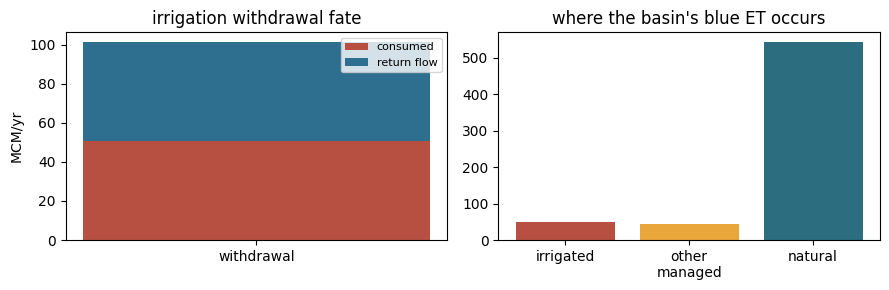

In [9]:
s4 = kw.sheet4_withdrawals(cubes['etincr'], cubes['sro'], cubes['perc'], lu, mask, RES, efficiency=IRR_EFFICIENCY)
print(f"irrigated land: consumed blue ET {s4['consumed_blue_ET']:.1f} MCM | withdrawal ≈ {s4['withdrawal_est']:.1f} MCM "
      f"(efficiency {IRR_EFFICIENCY}) | return flow {s4['recoverable_return']:.1f} MCM")
print(f"blue ET by land type: irrigated {s4['blue_ET_irrigated']:.1f} | other managed {s4['blue_ET_other_managed']:.1f} | "
      f"natural {s4['blue_ET_natural']:.1f}   (Sheet 1 blue ET {s1['ET_blue']:.1f})")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(['withdrawal'], [s4['consumed_blue_ET']], color='#B85042', label='consumed')
ax[0].bar(['withdrawal'], [s4['recoverable_return']], bottom=[s4['consumed_blue_ET']], color='#2E6E8E', label='return flow')
ax[0].set_ylabel('MCM/yr'); ax[0].legend(fontsize=8); ax[0].set_title('irrigation withdrawal fate')
ax[1].bar(['irrigated', 'other\nmanaged', 'natural'], [s4['blue_ET_irrigated'], s4['blue_ET_other_managed'], s4['blue_ET_natural']],
          color=['#B85042', '#E9A63B', '#2C6E7F'])
ax[1].set_title("where the basin's blue ET occurs"); plt.tight_layout(); plt.show()

## 7 · Cross-sheet consistency checks

**In plain terms.** Two kinds of check. The **identities** must hold exactly — if one fails, the inputs are misaligned (e.g. land-use cells with no WA+ class). The **plausibility checks** *can* fail, and that is the point: each ⚠️ is something to explain before the sheets go in front of a review panel.

In [10]:
chk = kw.sheet_consistency(s1, s2)
for k, v in chk.items(): print(f'{k:32s} = {v:+.3f} MCM')
assert all(abs(v) < 0.5 for v in chk.values()), 'identity check failed — inputs misaligned (unclassified land-use cells?)'
print('✅ identities hold\n\nPlausibility checks — explain every ⚠️ in the assumptions log:')
diag = kw.sheet_diagnostics(s1, s2, s4, open_water_E=globals().get('open_water_E'))
for r in diag:
    print(f"  {'✅' if r['ok'] else '⚠️ '} {r['check']:44s} {r['value']:>9.2f}   (limit {r['limit']})")

S2 total ET − S1 ET              = +0.001 MCM
S2 beneficial+nonben − total     = +0.000 MCM
S2 managed+natural − total       = +0.000 MCM
S2 sum of classes − total        = +0.000 MCM
✅ identities hold

Plausibility checks — explain every ⚠️ in the assumptions log:
  ✅ |closure term| / P (%)                            0.53   (limit 5.0)
  ✅ model green+blue ET vs satellite ET (%)           0.17   (limit 1.0)
  ⚠️  modelled vs observed outflow (%)                 25.53   (limit 15.0)
  ✅ S4 consumed > S1 blue ET (MCM)                    0.00   (limit 0.5)
  ⚠️  blue ET on natural land (% of blue ET)           85.25   (limit 25.0)
  ⚠️  water-body ET vs JRC open water (%)          3794107818.60   (limit 50.0)


### ✅ Checkpoints
Identities hold; every ⚠️ in the plausibility checks is explained (e.g. modelled outflow above the gauge → see Lab 4 calibration). Record the assumptions: beneficial-ET source, `IRR_EFFICIENCY`, `WP_CLASSES`, NDM units and the JRC threshold.

## 8 · Save the sheet summary

**Save the sheet summary.** Writes `wa_sheets_summary.json` (all four sheets + the consistency
residuals) to Drive — the machine-readable hand-off to Lab 6.

In [11]:
summary = {'sheet1': s1,
           'sheet2': {k: (v if not isinstance(v, dict) else {int(a): round(b, 2) for a, b in v.items()}) for k, v in s2.items()},
           'sheet3': s3, 'sheet3_whole_basin': s3_basin, 'sheet4': s4,
           'consistency': chk, 'diagnostics': diag,
           'assumptions': {'beneficial_split': s2['beneficial_source'], 'IRR_EFFICIENCY': IRR_EFFICIENCY,
                           'WP_CLASSES': list(WP_CLASSES) if WP_CLASSES else 'all', 'NDM_UNITS': NDM_UNITS,
                           'JRC_permanent_threshold_pct': globals().get('PERM'), 'outflow_observed': Q_OBS}}
json.dump(summary, open('wa_sheets_summary.json', 'w'), indent=2, default=float)
saved = kw.save_outputs(['wa_sheets_summary.json'], OUT_DIR)
print('saved', saved)

saved ['wa_sheets_summary.json']


## 8b · WA+-style figures of the four sheets

**What this does.** Draws Sheets 1–4 as WA+-style figures for the report (`wa_sheet1.png` … `wa_sheet4.png`, saved to Drive). The labels follow the WA+ definitions used above: landscape ET = green ET, incremental ET = blue ET, net inflow = P − closure. These are teaching figures, not the official IWMI sheet templates.

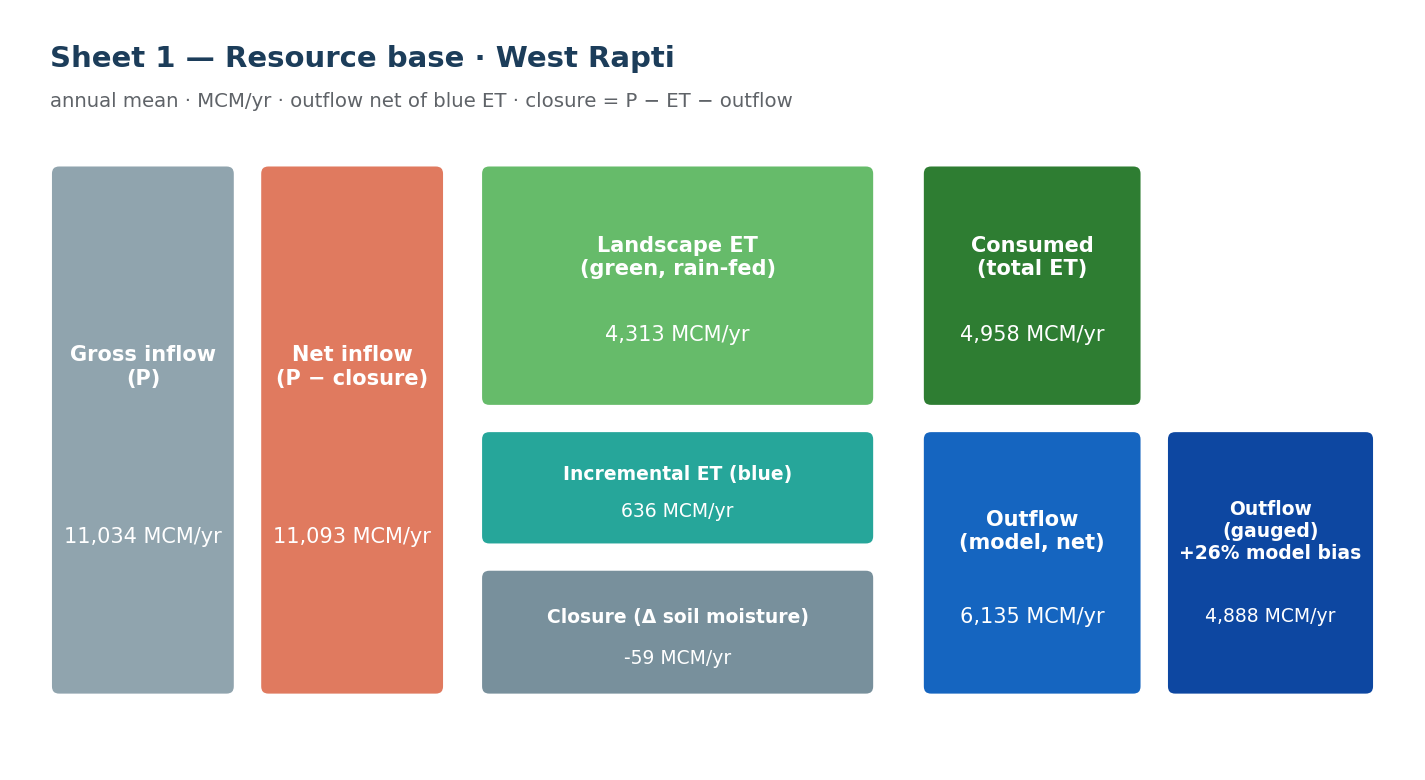

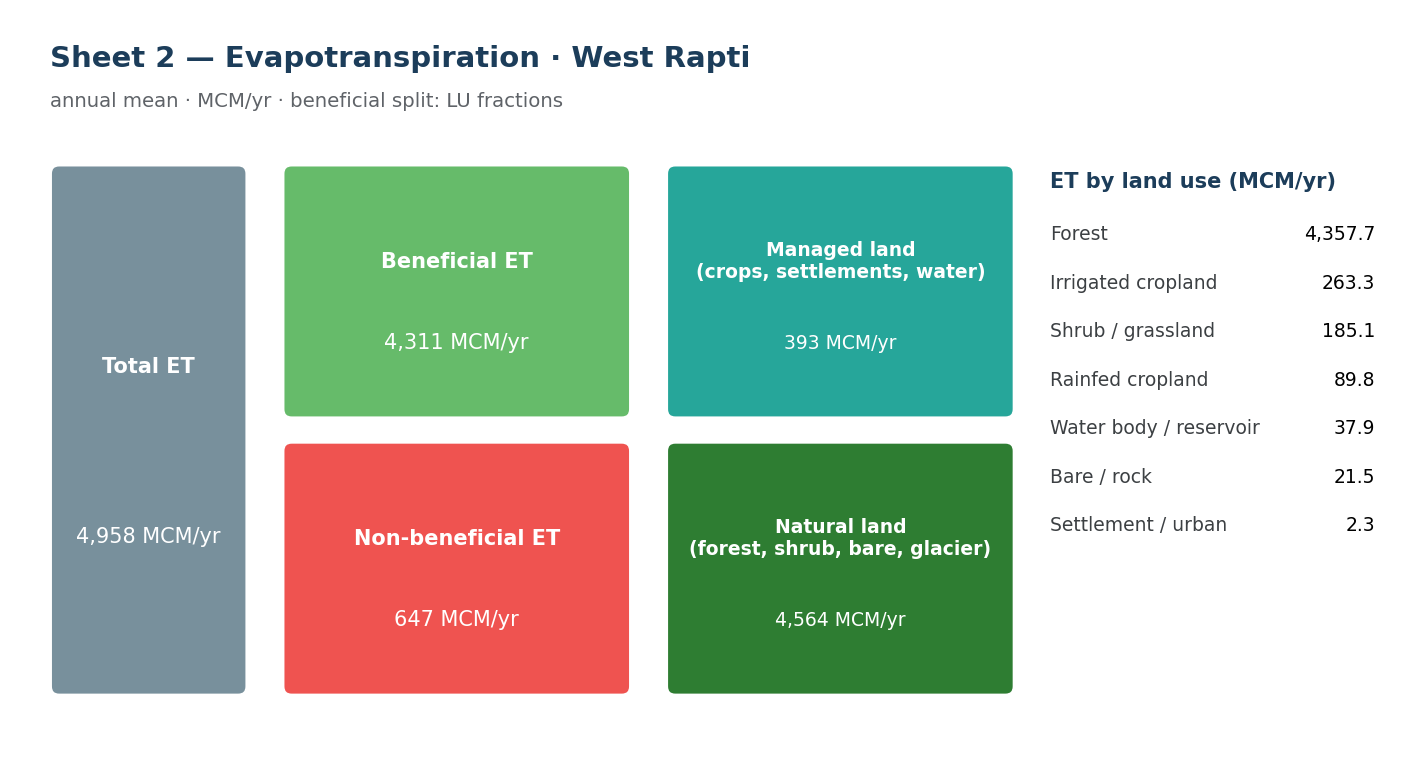

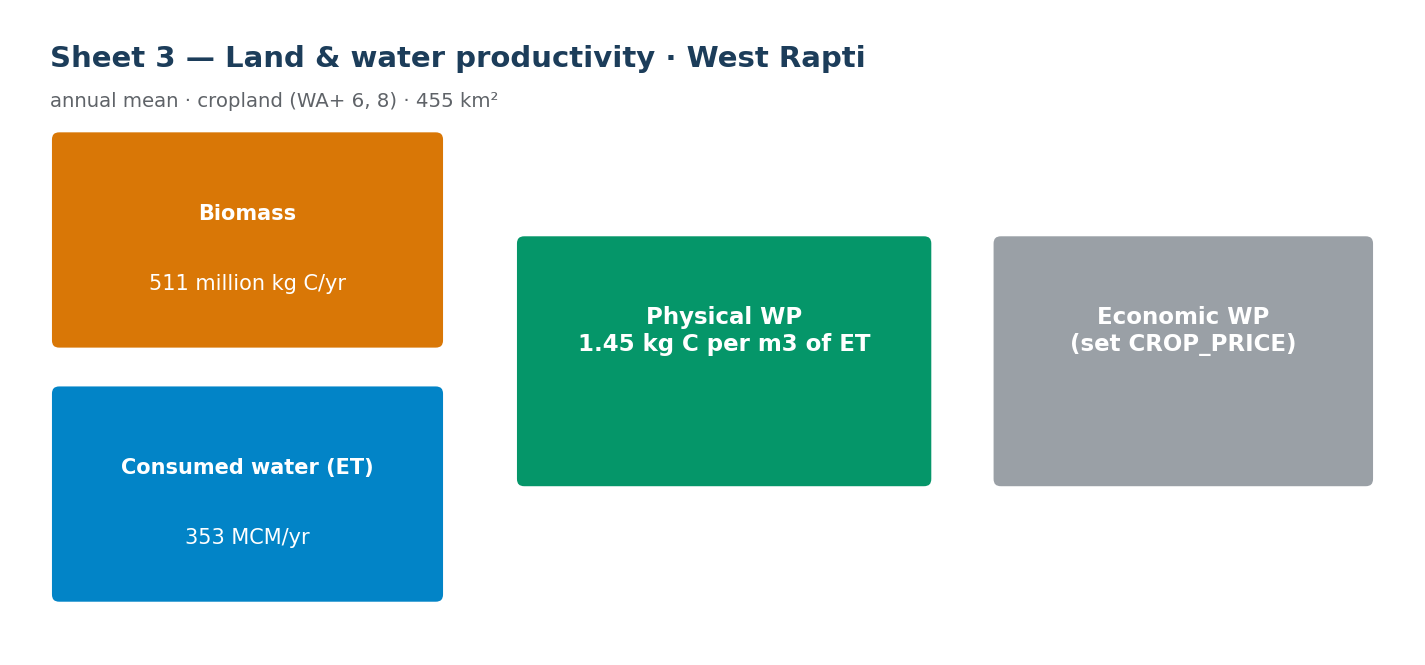

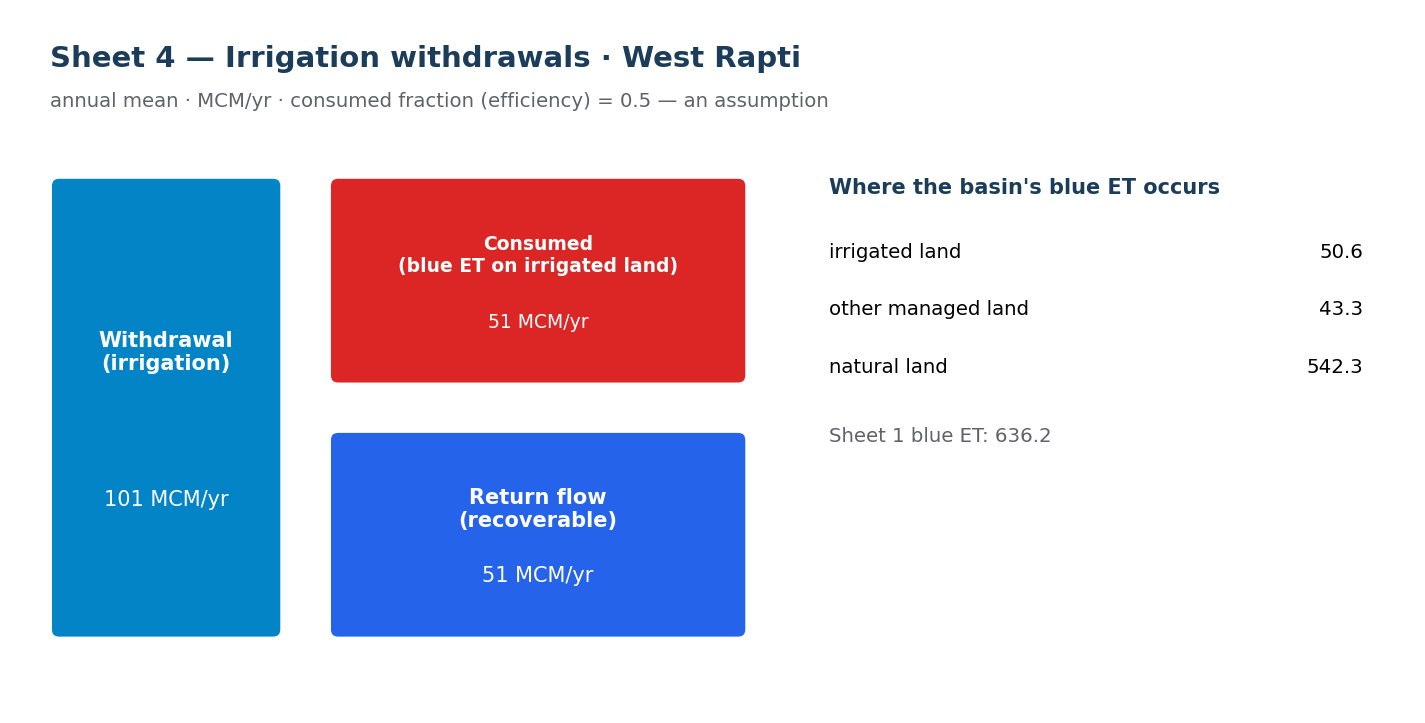

saved ['wa_sheet1.png', 'wa_sheet2.png', 'wa_sheet3.png', 'wa_sheet4.png']


In [12]:
# --- WA+-style sheet figures (one renderer; labels follow WA+ definitions) ---
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def _box(ax, x, y, w, h, title, value, color, txt='white', unit='MCM/yr', fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0,rounding_size=0.08', fc=color, ec='white', lw=2))
    ax.text(x + w / 2, y + h * 0.62, title, ha='center', va='center', color=txt, fontsize=fs, fontweight='bold', wrap=True)
    if value is not None:
        ax.text(x + w / 2, y + h * 0.3, f'{value:,.0f} {unit}' if abs(value) >= 10 else f'{value:,.2f} {unit}',
                ha='center', va='center', color=txt, fontsize=fs)

def _frame(title, sub, w=12, h=6.5):
    fig, ax = plt.subplots(figsize=(w, h), dpi=150); ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis('off')
    ax.text(0.3, h - 0.45, title, fontsize=14, fontweight='bold', color='#1C3D5A')
    ax.text(0.3, h - 0.8, sub, fontsize=9.5, color='#5F6368')
    return fig, ax

def draw_sheet1(s1, basin='West Rapti', period='annual mean'):
    fig, ax = _frame(f'Sheet 1 — Resource base · {basin}', f'{period} · MCM/yr · outflow net of blue ET · closure = P − ET − outflow')
    _box(ax, 0.3, 0.6, 1.6, 4.6, 'Gross inflow\n(P)', s1['gross_inflow_P'], '#90A4AE')
    _box(ax, 2.1, 0.6, 1.6, 4.6, 'Net inflow\n(P − closure)', s1['net_inflow'], '#E07A5F')
    _box(ax, 4.0, 3.1, 3.4, 2.1, 'Landscape ET\n(green, rain-fed)', s1.get('ET_green'), '#66BB6A')
    _box(ax, 4.0, 1.9, 3.4, 1.0, 'Incremental ET (blue)', s1.get('ET_blue'), '#26A69A', fs=9)
    _box(ax, 4.0, 0.6, 3.4, 1.1, 'Closure (Δ soil moisture)', s1['closure_term'], '#78909C', fs=9)
    _box(ax, 7.8, 3.1, 1.9, 2.1, 'Consumed\n(total ET)', s1['ET_depleted'], '#2E7D32')
    _box(ax, 7.8, 0.6, 1.9, 2.3, 'Outflow\n(model, net)', s1['outflow_est'], '#1565C0')
    if s1.get('outflow_observed') is not None:
        _box(ax, 9.9, 0.6, 1.8, 2.3, f"Outflow\n(gauged)\n{s1['outflow_bias_pct']:+.0f}% model bias",
             s1['outflow_observed'], '#0D47A1', fs=9)
    plt.savefig('wa_sheet1.png', bbox_inches='tight', facecolor='white'); plt.show()

def draw_sheet2(s2, classes, basin='West Rapti', period='annual mean'):
    fig, ax = _frame(f'Sheet 2 — Evapotranspiration · {basin}',
                     f"{period} · MCM/yr · beneficial split: {s2.get('beneficial_source', 'LU fractions')}")
    _box(ax, 0.3, 0.6, 1.7, 4.6, 'Total ET', s2['total'], '#78909C')
    _box(ax, 2.3, 3.0, 3.0, 2.2, 'Beneficial ET', s2['beneficial'], '#66BB6A')
    _box(ax, 2.3, 0.6, 3.0, 2.2, 'Non-beneficial ET', s2['non_beneficial'], '#EF5350')
    _box(ax, 5.6, 3.0, 3.0, 2.2, 'Managed land\n(crops, settlements, water)', s2['managed'], '#26A69A', fs=9)
    _box(ax, 5.6, 0.6, 3.0, 2.2, 'Natural land\n(forest, shrub, bare, glacier)', s2['natural'], '#2E7D32', fs=9)
    rows = sorted(((classes.get(c, (None, str(c)))[1], v) for c, v in s2['by_class'].items() if v > 0.05), key=lambda r: -r[1])
    ax.text(8.9, 5.0, 'ET by land use (MCM/yr)', fontsize=10, fontweight='bold', color='#1C3D5A')
    for i, (n, v) in enumerate(rows[:9]):
        ax.text(8.9, 4.55 - 0.42 * i, n, fontsize=9, color='#3C4043'); ax.text(11.7, 4.55 - 0.42 * i, f'{v:,.1f}', fontsize=9, ha='right')
    plt.savefig('wa_sheet2.png', bbox_inches='tight', facecolor='white'); plt.show()

def draw_sheet3(s3, basin='West Rapti', period='annual mean'):
    where = 'cropland (WA+ ' + ', '.join(map(str, s3['classes'])) + ')' if s3['classes'] != 'all' else 'whole basin'
    fig, ax = _frame(f'Sheet 3 — Land & water productivity · {basin}', f"{period} · {where} · {s3['area_km2']:,.0f} km²", h=5.5)
    unit = s3['units'].split(' per ')[0]
    _box(ax, 0.3, 2.6, 3.4, 1.9, 'Biomass', s3['biomass_annual'] / 1e6, '#D97706', unit=f'million {unit}/yr')
    _box(ax, 0.3, 0.4, 3.4, 1.9, 'Consumed water (ET)', s3['ET_m3'] / 1e6, '#0284C7', unit='MCM/yr')
    _box(ax, 4.3, 1.4, 3.6, 2.2, f"Physical WP\n{s3['WP_physical']:.2f} {s3['units']}", None, '#059669', fs=11)
    if s3.get('WP_economic') is not None:
        _box(ax, 8.4, 1.4, 3.3, 2.2, f"Economic WP\n{s3['WP_economic']:.3f} $ per m³", None, '#7C3AED', fs=11)
    else:
        _box(ax, 8.4, 1.4, 3.3, 2.2, 'Economic WP\n(set CROP_PRICE)', None, '#9AA0A6', fs=11)
    plt.savefig('wa_sheet3.png', bbox_inches='tight', facecolor='white'); plt.show()

def draw_sheet4(s4, s1=None, basin='West Rapti', period='annual mean'):
    fig, ax = _frame(f'Sheet 4 — Irrigation withdrawals · {basin}',
                     f"{period} · MCM/yr · consumed fraction (efficiency) = {s4['efficiency']} — an assumption", h=6)
    _box(ax, 0.3, 0.6, 2.0, 4.0, 'Withdrawal\n(irrigation)', s4['withdrawal_est'], '#0284C7')
    _box(ax, 2.7, 2.8, 3.6, 1.8, 'Consumed\n(blue ET on irrigated land)', s4['consumed_blue_ET'], '#DC2626', fs=9)
    _box(ax, 2.7, 0.6, 3.6, 1.8, 'Return flow\n(recoverable)', s4['recoverable_return'], '#2563EB')
    ax.text(7.0, 4.45, "Where the basin's blue ET occurs", fontsize=10, fontweight='bold', color='#1C3D5A')
    tot = (s1 or {}).get('ET_blue')
    for i, (n, v) in enumerate((('irrigated land', s4['blue_ET_irrigated']), ('other managed land', s4['blue_ET_other_managed']),
                                ('natural land', s4['blue_ET_natural']))):
        ax.text(7.0, 3.9 - 0.5 * i, n, fontsize=9.5); ax.text(11.6, 3.9 - 0.5 * i, f'{v:,.1f}', fontsize=9.5, ha='right')
    if tot: ax.text(7.0, 2.3, f'Sheet 1 blue ET: {tot:,.1f}', fontsize=9.5, color='#5F6368')
    plt.savefig('wa_sheet4.png', bbox_inches='tight', facecolor='white'); plt.show()


draw_sheet1(s1); draw_sheet2(s2, kw.WAPLUS_CLASSES); draw_sheet3(s3); draw_sheet4(s4, s1)
print('saved', kw.save_outputs(['wa_sheet1.png', 'wa_sheet2.png', 'wa_sheet3.png', 'wa_sheet4.png'], OUT_DIR))

## 9 · Interactive — crop price & the beneficial-ET method  🎛️

Two live controls: the **crop-price slider** re-computes Sheet 3 economic water productivity ($ per m³) for a farm-gate price per kg C; the method comparison re-runs Sheet 2 both ways — land-use fractions vs the physical WaPOR-transpiration split (if `transp.nc` was loaded) — so you can see how much the beneficial share depends on that choice. Runs offline; nothing is overwritten.

In [13]:
# --- live: crop price -> economic WP, and beneficial-ET method comparison ---
import ipywidgets as W, matplotlib.pyplot as plt
from IPython.display import display

_price = W.FloatSlider(value=(CROP_PRICE or 0.20), min=0.0, max=1.0, step=0.02,
                       description='$/kg C', readout_format='.2f')
_out = W.Output()
def _wp(_):
    with _out:
        _out.clear_output()
        p = _price.value if _price.value > 0 else None
        s3b = kw.sheet3_productivity(ndm, cubes['ET'], lu, mask, RES, price=p, classes=WP_CLASSES, units=NDM_UNITS)
        msg = f"physical WP = {s3b['WP_physical']:.3g} {s3b['units']}"
        if p: msg += f"   |   economic WP = {s3b['WP_economic']:.3g} $/m³  (at ${p:.2f}/kg C)"
        print(msg)
        # beneficial split both ways
        lu_s = kw.sheet2_et(cubes['ET'], lu, mask, RES)
        rows = [('LU fractions', lu_s['beneficial'], lu_s['non_beneficial'])]
        if TRANSP is not None:
            t_s = kw.sheet2_et(cubes['ET'], lu, mask, RES, T=TRANSP)
            rows.append(('WaPOR transpiration', t_s['beneficial'], t_s['non_beneficial']))
        fig, ax = plt.subplots(figsize=(6,3)); x = range(len(rows))
        ax.bar([i-0.18 for i in x], [r[1] for r in rows], width=0.36, label='beneficial', color='#4C9A6B')
        ax.bar([i+0.18 for i in x], [r[2] for r in rows], width=0.36, label='non-beneficial', color='#B85042')
        ax.set_xticks(list(x)); ax.set_xticklabels([r[0] for r in rows]); ax.set_ylabel('MCM/yr')
        ax.legend(fontsize=8); ax.set_title('Sheet 2 beneficial split — method comparison'); plt.show()
        if TRANSP is None:
            print('(load transp.nc from Lab 2 to add the physical WaPOR-transpiration split)')
_price.observe(lambda c: _wp(None), names='value')
display(_price, _out); _wp(None)

FloatSlider(value=0.2, description='$/kg C', max=1.0, step=0.02)

Output()

## What feeds Lab 6
The sheet volumes, the beneficial/managed splits, and the modelled outflow feed the synthesis: utilisable flow after environmental & committed flows (both Nepal standards), scenarios, and the policy brief.